# Unemployment Analysis in India Using Python

## Introduction

This project analyzes unemployment rate data in India using Python.
The analysis focuses on unemployment trends across different regions,
changes over time, rural and urban unemployment, and the impact of
the COVID-19 period on unemployment rates.

Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn are
used for data cleaning, analysis, and visualization.


## Objectives

- Analyze unemployment rates in India.
- Clean and prepare the datasets for analysis.
- Explore unemployment trends over time.
- Compare unemployment across states and regions.
- Compare rural and urban unemployment.
- Analyze employment and labour participation rates.
- Investigate changes in unemployment during the COVID-19 period.
- Identify important patterns and trends using visualizations.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [6]:
df1 = pd.read_csv("Unemployment_in_India.csv")
df2 = pd.read_csv("Unemployment_Rate_upto_11_2020.csv")

In [7]:
print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)

Dataset 1: (768, 7)
Dataset 2: (267, 9)


In [8]:
print(df1.head())

           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019    Monthly                              3.65   
1  Andhra Pradesh   30-06-2019    Monthly                              3.05   
2  Andhra Pradesh   31-07-2019    Monthly                              3.75   
3  Andhra Pradesh   31-08-2019    Monthly                              3.32   
4  Andhra Pradesh   30-09-2019    Monthly                              5.17   

    Estimated Employed   Estimated Labour Participation Rate (%)   Area  
0           11999139.0                                     43.24  Rural  
1           11755881.0                                     42.05  Rural  
2           12086707.0                                     43.50  Rural  
3           12285693.0                                     43.97  Rural  
4           12256762.0                                     44.68  Rural  


In [9]:
print(df2.head())

           Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-01-2020          M                              5.48   
1  Andhra Pradesh   29-02-2020          M                              5.83   
2  Andhra Pradesh   31-03-2020          M                              5.79   
3  Andhra Pradesh   30-04-2020          M                             20.51   
4  Andhra Pradesh   31-05-2020          M                             17.43   

    Estimated Employed   Estimated Labour Participation Rate (%) Region.1  \
0             16635535                                     41.02    South   
1             16545652                                     40.90    South   
2             15881197                                     39.18    South   
3             11336911                                     33.10    South   
4             12988845                                     36.46    South   

   longitude  latitude  
0    15.9129     79.74  
1    15.9129

In [10]:
df1.columns = df1.columns.str.strip()

for col in df1.select_dtypes(include="object").columns:
    df1[col] = df1[col].str.strip()

df1["Date"] = pd.to_datetime(
    df1["Date"],
    format="%d-%m-%Y"
)

print(df1.isnull().sum())
print("Duplicates:", df1.duplicated().sum())

Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64
Duplicates: 27


In [11]:
df1 = df1.drop_duplicates()

In [12]:
df2.columns = df2.columns.str.strip()

for col in df2.select_dtypes(include="object").columns:
    df2[col] = df2[col].str.strip()

df2["Date"] = pd.to_datetime(
    df2["Date"],
    format="%d-%m-%Y"
)

print(df2.isnull().sum())
print("Duplicates:", df2.duplicated().sum())

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Region.1                                   0
longitude                                  0
latitude                                   0
dtype: int64
Duplicates: 0


In [13]:
df2 = df2.drop_duplicates()

In [14]:
monthly_unemployment = df1.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

print(monthly_unemployment)

Date
2019-05-31     8.874259
2019-06-30     9.303333
2019-07-31     9.033889
2019-08-31     9.637925
2019-09-30     9.051731
2019-10-31     9.900909
2019-11-30     9.868364
2019-12-31     9.497358
2020-01-31     9.950755
2020-02-29     9.964717
2020-03-31    10.700577
2020-04-30    23.641569
2020-05-31    24.875294
2020-06-30    11.903600
Name: Estimated Unemployment Rate (%), dtype: float64


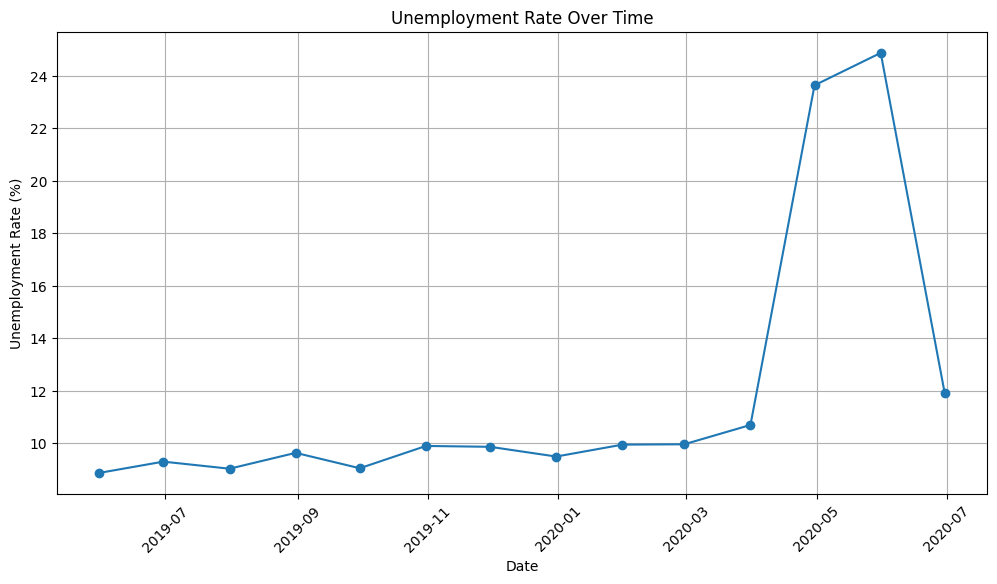

In [15]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o"
)

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [16]:
covid_data = df2.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

print(covid_data)

Date
2020-01-31     9.196538
2020-02-29     9.266154
2020-03-31    10.782593
2020-04-30    22.236154
2020-05-31    23.244444
2020-06-30    10.911111
2020-07-31     9.834444
2020-08-31    10.313333
2020-09-30     8.705926
2020-10-31     8.026296
Name: Estimated Unemployment Rate (%), dtype: float64


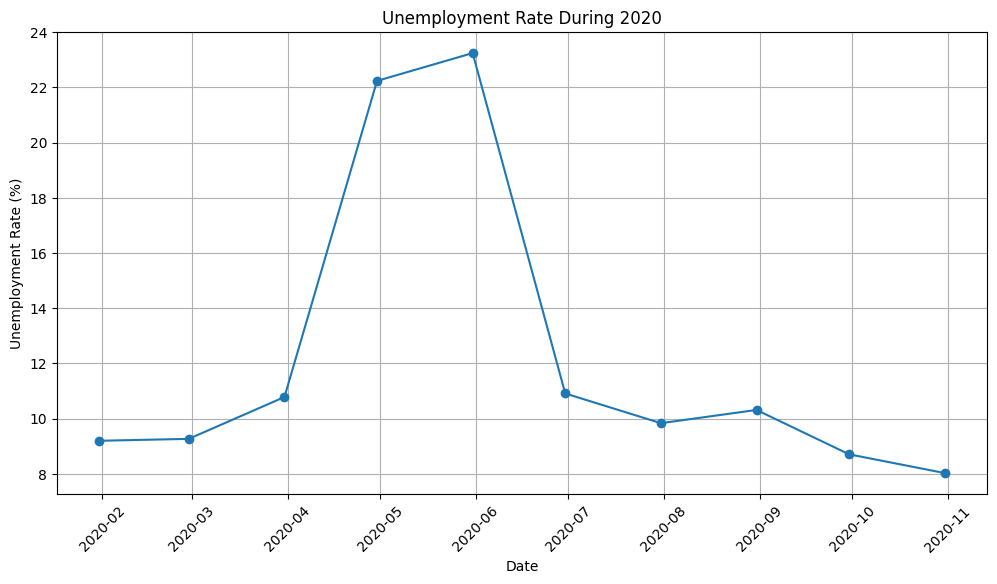

In [17]:
plt.figure(figsize=(12, 6))

plt.plot(
    covid_data.index,
    covid_data.values,
    marker="o"
)

plt.title("Unemployment Rate During 2020")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [18]:
area_rate = df1.groupby("Area")[
    "Estimated Unemployment Rate (%)"
].mean()

print(area_rate)

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


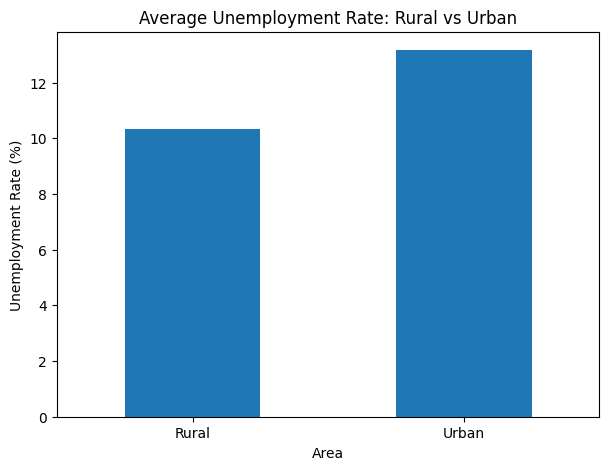

In [19]:
plt.figure(figsize=(7, 5))

area_rate.plot(kind="bar")

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=0)

plt.show()

In [20]:
state_rate = df2.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean()

state_rate = state_rate.sort_values(ascending=False)

print(state_rate)

Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64


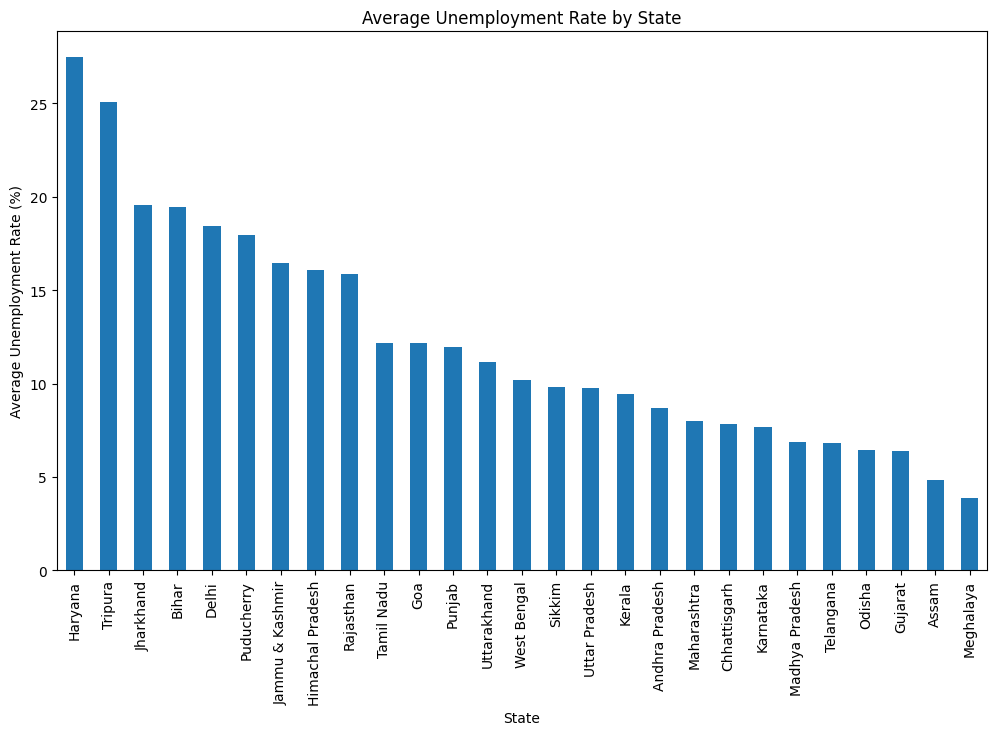

In [21]:
plt.figure(figsize=(12, 7))

state_rate.plot(kind="bar")

plt.title("Average Unemployment Rate by State")
plt.xlabel("State")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=90)

plt.show()

In [22]:
print(df2.columns)

Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employed', 'Estimated Labour Participation Rate (%)',
       'Region.1', 'longitude', 'latitude'],
      dtype='object')


In [23]:
df2 = df2.rename(columns={
    "Region.1": "Zone"
})

In [24]:
regional_rate = df2.groupby("Zone")[
    "Estimated Unemployment Rate (%)"
].mean()

print(regional_rate)

Zone
East         13.916000
North        15.889620
Northeast    10.950263
South        10.454667
West          8.239000
Name: Estimated Unemployment Rate (%), dtype: float64


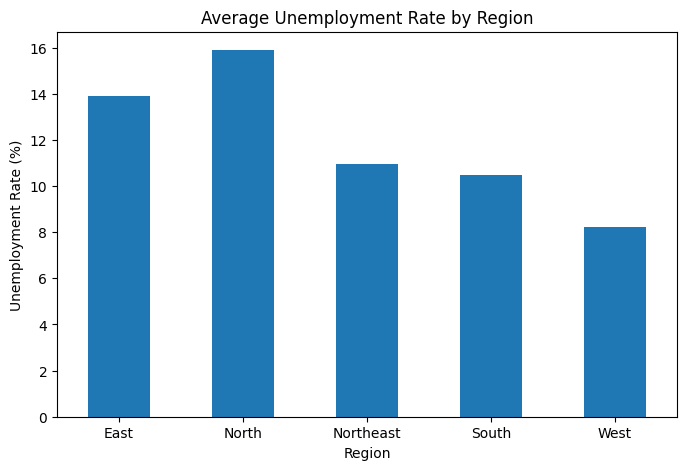

In [25]:
plt.figure(figsize=(8, 5))

regional_rate.plot(kind="bar")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Region")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=0)

plt.show()

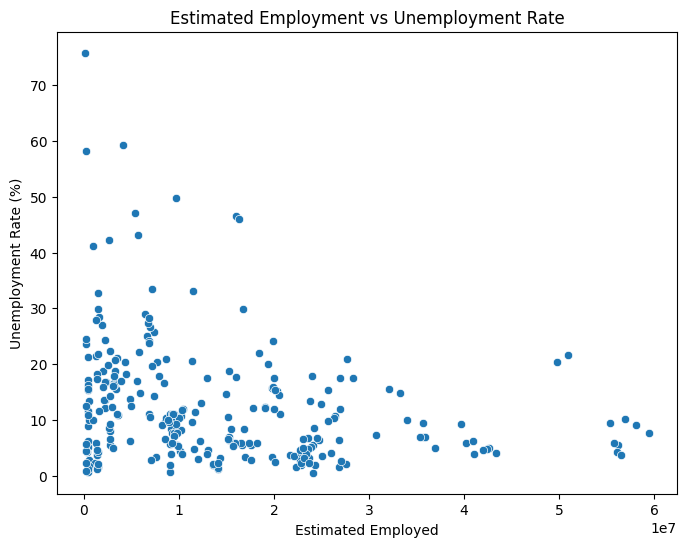

In [26]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2,
    x="Estimated Employed",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Estimated Employment vs Unemployment Rate")
plt.xlabel("Estimated Employed")
plt.ylabel("Unemployment Rate (%)")

plt.show()

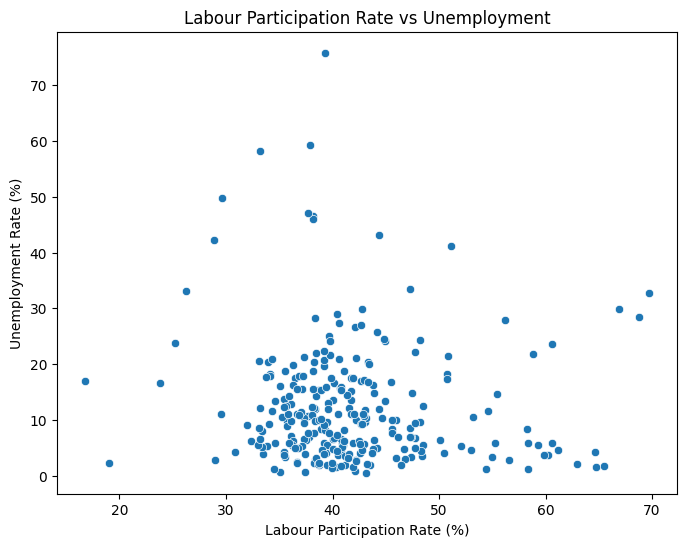

In [27]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2,
    x="Estimated Labour Participation Rate (%)",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Labour Participation Rate vs Unemployment")
plt.xlabel("Labour Participation Rate (%)")
plt.ylabel("Unemployment Rate (%)")

plt.show()

In [28]:
correlation = df2[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

print(correlation)

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                 1.000000   
Estimated Employed                                             -0.245176   
Estimated Labour Participation Rate (%)                        -0.073540   

                                         Estimated Employed  \
Estimated Unemployment Rate (%)                   -0.245176   
Estimated Employed                                 1.000000   
Estimated Labour Participation Rate (%)           -0.047948   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                        -0.073540  
Estimated Employed                                                     -0.047948  
Estimated Labour Participation Rate (%)                                 1.000000  


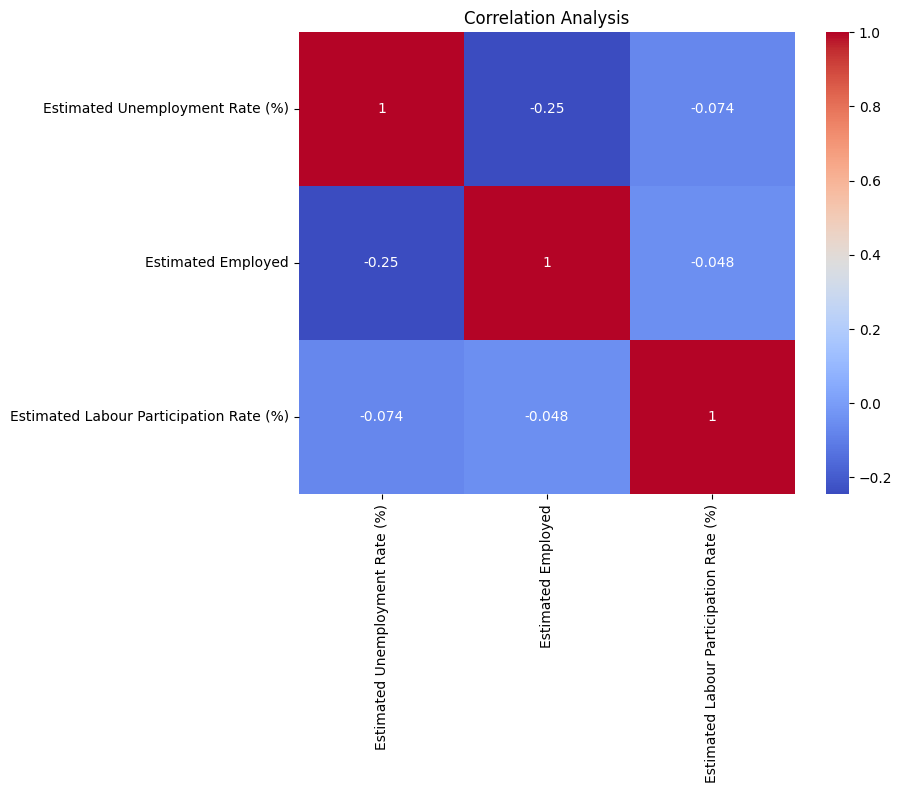

In [29]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Analysis")

plt.show()

In [30]:
print("DATASET 1")
print(df1.head())
print(df1.shape)
print(df1.columns)

print("\nDATASET 2")
print(df2.head())
print(df2.shape)
print(df2.columns)

DATASET 1
           Region       Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh 2019-05-31   Monthly                             3.65   
1  Andhra Pradesh 2019-06-30   Monthly                             3.05   
2  Andhra Pradesh 2019-07-31   Monthly                             3.75   
3  Andhra Pradesh 2019-08-31   Monthly                             3.32   
4  Andhra Pradesh 2019-09-30   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  
0          11999139.0                                    43.24  Rural  
1          11755881.0                                    42.05  Rural  
2          12086707.0                                    43.50  Rural  
3          12285693.0                                    43.97  Rural  
4          12256762.0                                    44.68  Rural  
(741, 7)
Index(['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)',
       'Estimated Employe

In [31]:
print("Dataset 1 information:")
df1.info()

print("\nDataset 1 missing values:")
print(df1.isnull().sum())

print("\nDataset 2 information:")
df2.info()

print("\nDataset 2 missing values:")
print(df2.isnull().sum())

Dataset 1 information:
<class 'pandas.core.frame.DataFrame'>
Index: 741 entries, 0 to 753
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
dtypes: datetime64[ns](1), float64(3), object(3)
memory usage: 46.3+ KB

Dataset 1 missing values:
Region                                     1
Date                                     

In [32]:
print(df1[df1.isnull().any(axis=1)])

    Region Date Frequency  Estimated Unemployment Rate (%)  \
359    NaN  NaT       NaN                              NaN   

     Estimated Employed  Estimated Labour Participation Rate (%) Area  
359                 NaN                                      NaN  NaN  


In [33]:
print(df2[df2.isnull().any(axis=1)])


Empty DataFrame
Columns: [Region, Date, Frequency, Estimated Unemployment Rate (%), Estimated Employed, Estimated Labour Participation Rate (%), Zone, longitude, latitude]
Index: []


In [34]:
print(df2.isnull().sum())

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Zone                                       0
longitude                                  0
latitude                                   0
dtype: int64


In [35]:
print("Before cleaning:", df1.shape)

df1 = df1.dropna(how="all")

print("After cleaning:", df1.shape)

Before cleaning: (741, 7)
After cleaning: (740, 7)


In [36]:
print("Dataset 1 duplicates:", df1.duplicated().sum())
print("Dataset 2 duplicates:", df2.duplicated().sum())

Dataset 1 duplicates: 0
Dataset 2 duplicates: 0


In [37]:
df1 = df1.drop_duplicates()
df2 = df2.drop_duplicates()

In [38]:
df1 = df1.reset_index(drop=True)
df2 = df2.reset_index(drop=True)

In [39]:
print("DATASET 1")
print(df1.shape)
print(df1.isnull().sum())

print("\nDATASET 2")
print(df2.shape)
print(df2.isnull().sum())

DATASET 1
(740, 7)
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64

DATASET 2
(267, 9)
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Zone                                       0
longitude                                  0
latitude                                   0
dtype: int64


In [40]:
# Calculate average unemployment rate for each date

monthly_unemployment = df1.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

print(monthly_unemployment)

Date
2019-05-31     8.874259
2019-06-30     9.303333
2019-07-31     9.033889
2019-08-31     9.637925
2019-09-30     9.051731
2019-10-31     9.900909
2019-11-30     9.868364
2019-12-31     9.497358
2020-01-31     9.950755
2020-02-29     9.964717
2020-03-31    10.700577
2020-04-30    23.641569
2020-05-31    24.875294
2020-06-30    11.903600
Name: Estimated Unemployment Rate (%), dtype: float64


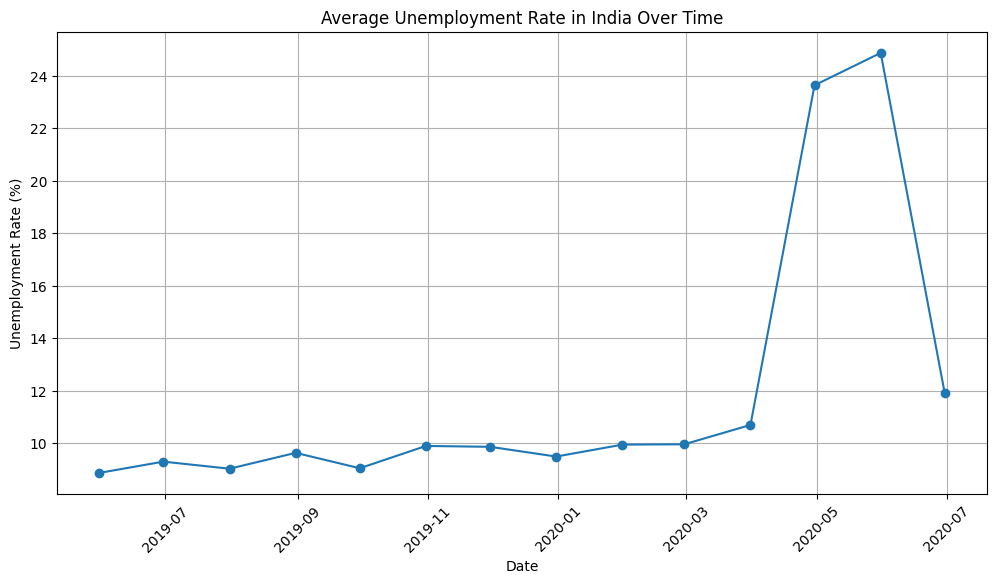

In [41]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_unemployment.index,
    monthly_unemployment.values,
    marker="o"
)

plt.title("Average Unemployment Rate in India Over Time")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [42]:
area_unemployment = df1.groupby("Area")[
    "Estimated Unemployment Rate (%)"
].mean()

print(area_unemployment)

Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


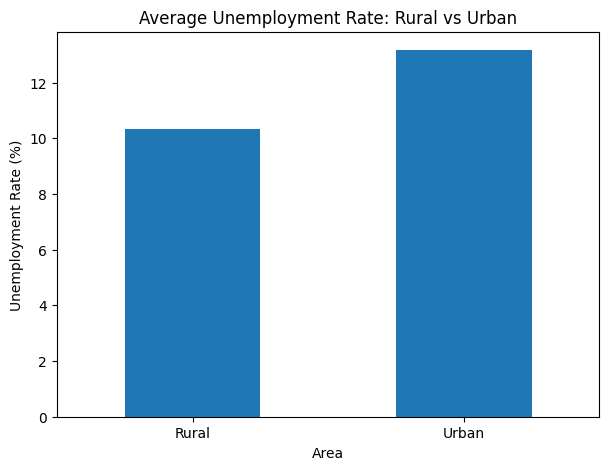

In [43]:
plt.figure(figsize=(7, 5))

area_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=0)

plt.show()

## State-wise Unemployment Analysis

This section compares the average unemployment rate across different
states/regions in the dataset.

In [44]:
state_unemployment = df2.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean()

state_unemployment = state_unemployment.sort_values(
    ascending=False
)

print(state_unemployment)

Region
Haryana             27.477000
Tripura             25.055000
Jharkhand           19.539000
Bihar               19.471000
Delhi               18.414000
Puducherry          17.942000
Jammu & Kashmir     16.477778
Himachal Pradesh    16.065000
Rajasthan           15.868000
Tamil Nadu          12.187000
Goa                 12.167000
Punjab              11.981000
Uttarakhand         11.156000
West Bengal         10.192000
Sikkim               9.792500
Uttar Pradesh        9.737000
Kerala               9.434000
Andhra Pradesh       8.664000
Maharashtra          7.979000
Chhattisgarh         7.819000
Karnataka            7.668000
Madhya Pradesh       6.854000
Telangana            6.833000
Odisha               6.462000
Gujarat              6.376000
Assam                4.856000
Meghalaya            3.866000
Name: Estimated Unemployment Rate (%), dtype: float64


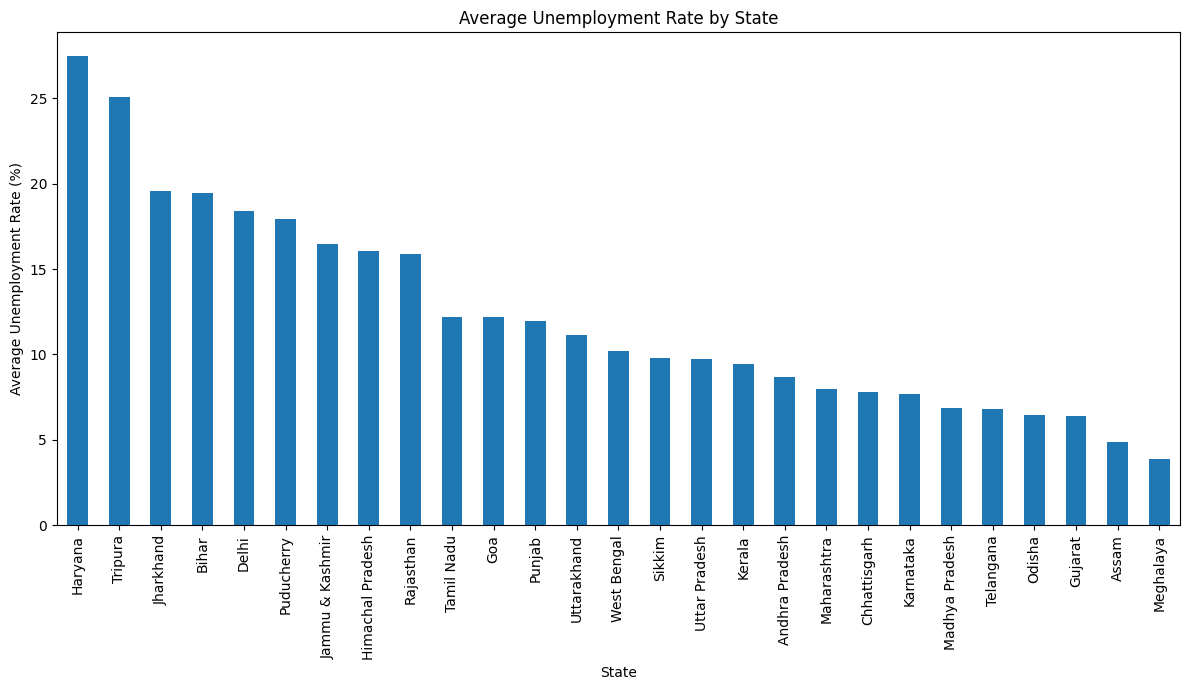

In [45]:
plt.figure(figsize=(12, 7))

state_unemployment.plot(kind="bar")

plt.title("Average Unemployment Rate by State")
plt.xlabel("State")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [46]:
covid_monthly = df2.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

print(covid_monthly)

Date
2020-01-31     9.196538
2020-02-29     9.266154
2020-03-31    10.782593
2020-04-30    22.236154
2020-05-31    23.244444
2020-06-30    10.911111
2020-07-31     9.834444
2020-08-31    10.313333
2020-09-30     8.705926
2020-10-31     8.026296
Name: Estimated Unemployment Rate (%), dtype: float64


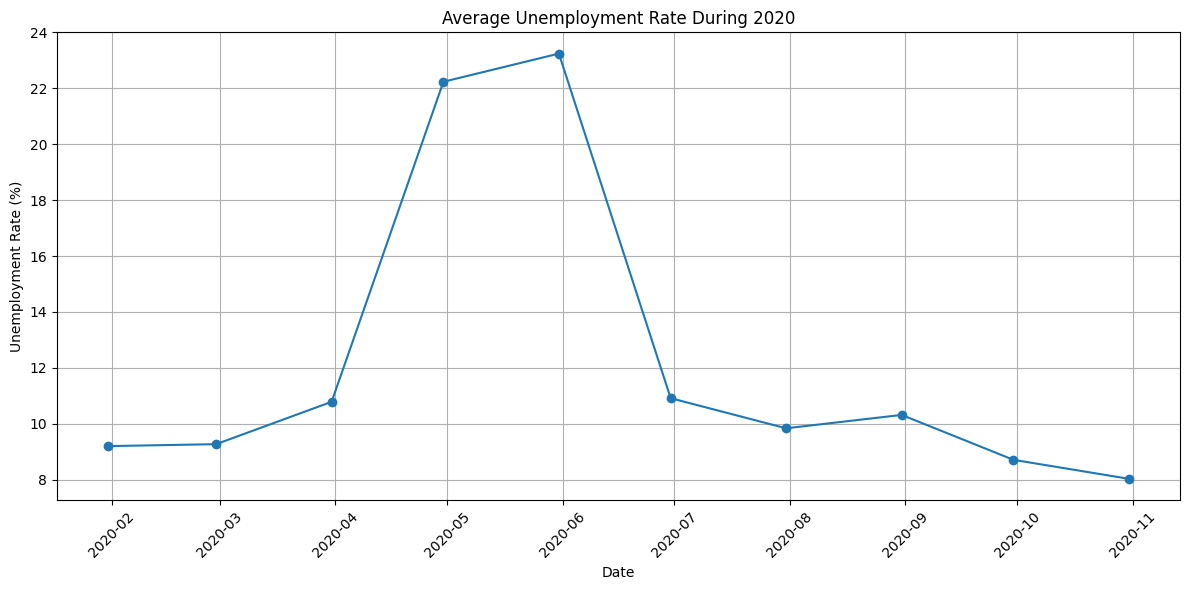

In [47]:
plt.figure(figsize=(12, 6))

plt.plot(
    covid_monthly.index,
    covid_monthly.values,
    marker="o"
)

plt.title("Average Unemployment Rate During 2020")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

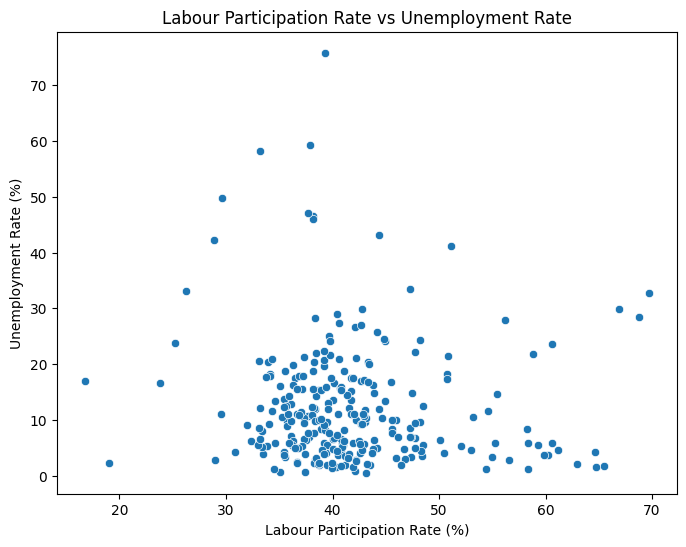

In [48]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2,
    x="Estimated Labour Participation Rate (%)",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Labour Participation Rate vs Unemployment Rate")
plt.xlabel("Labour Participation Rate (%)")
plt.ylabel("Unemployment Rate (%)")

plt.show()

In [49]:
plt.show()

In [50]:
correlation = df2[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

print(correlation)

                                         Estimated Unemployment Rate (%)  \
Estimated Unemployment Rate (%)                                  1.00000   
Estimated Labour Participation Rate (%)                         -0.07354   

                                         Estimated Labour Participation Rate (%)  
Estimated Unemployment Rate (%)                                         -0.07354  
Estimated Labour Participation Rate (%)                                  1.00000  


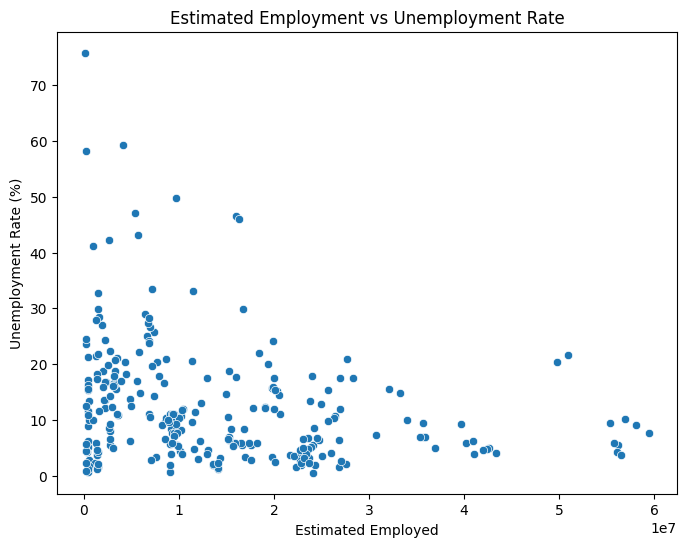

In [51]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df2,
    x="Estimated Employed",
    y="Estimated Unemployment Rate (%)"
)

plt.title("Estimated Employment vs Unemployment Rate")
plt.xlabel("Estimated Employed")
plt.ylabel("Unemployment Rate (%)")

plt.show()

In [52]:
employment_correlation = df2[
    [
        "Estimated Employed",
        "Estimated Unemployment Rate (%)"
    ]
].corr()

print(employment_correlation)

                                 Estimated Employed  \
Estimated Employed                         1.000000   
Estimated Unemployment Rate (%)           -0.245176   

                                 Estimated Unemployment Rate (%)  
Estimated Employed                                     -0.245176  
Estimated Unemployment Rate (%)                         1.000000  


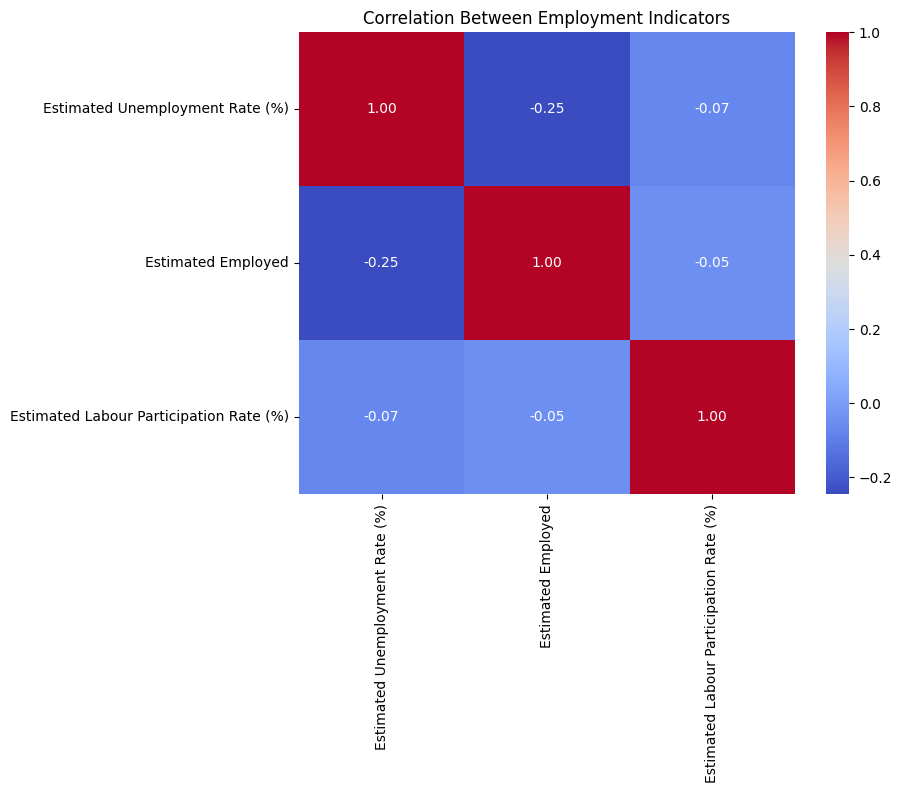

In [53]:
correlation = df2[
    [
        "Estimated Unemployment Rate (%)",
        "Estimated Employed",
        "Estimated Labour Participation Rate (%)"
    ]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Between Employment Indicators")

plt.show()